In [5]:
!pip install nltk scikit-learn pandas matplotlib seaborn gradio

In [6]:
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
nltk.download('wordnet')

print("NLTK resource downloaded successfully!")

NLTK resource downloaded successfully!


[nltk_data] Downloading package wordnet to C:\Users\siyag/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [9]:
corpus = {

    "HEART_FUNCTIONS": [
        "How does the heart maintain blood circulation?",
        "Why does the heart beat continuously?",
        "What happens when the heart pumps blood?",
        "How do heart chambers work together?",
        "What role do heart valves perform?",
        "Why does the body need oxygen rich blood?",
        "How does the heartbeat change during activity?",
        "What controls the rhythm of the heart?"
    ],

    "LIFESTYLE_IMPACT": [
        "Can sitting for long hours affect circulation?",
        "How does poor sleep influence heart wellness?",
        "Does daily stress affect heart rhythm?",
        "Can lack of physical activity weaken the heart?",
        "How does tobacco exposure affect blood vessels?",
        "Does excessive screen time affect heart health indirectly?",
        "Can regular walking support cardiovascular fitness?",
        "How does maintaining a healthy weight help the heart?"
    ],

    "WARNING_SIGNALS": [
        "Why do I feel breathless after minor activity?",
        "What could frequent heart fluttering indicate?",
        "Why do I experience unusual tiredness?",
        "Can swelling in the ankles be related to heart problems?",
        "What does unexplained chest tightness mean?",
        "Why do I sometimes feel faint or lightheaded?",
        "Can unusual sweating accompany cardiac problems?",
        "What changes in heartbeat should not be ignored?"
    ],

    "NUTRITION_HABITS": [
        "How does excess salt influence blood pressure?",
        "Are oats beneficial for cardiovascular wellness?",
        "Can eating too much saturated fat affect arteries?",
        "Why are fruits important in a heart friendly diet?",
        "How does dietary fibre support cholesterol management?",
        "Can frequent sugary drinks affect heart health?",
        "Are nuts useful for maintaining healthy cholesterol?",
        "Why should processed foods be limited for heart wellness?"
    ],

    "CARDIAC_SCREENING": [
        "What information does an ECG provide?",
        "How can an echocardiogram examine heart structure?",
        "Why is a lipid profile recommended?",
        "What is the purpose of a treadmill cardiac test?",
        "How does blood pressure monitoring help assess risk?",
        "What can a Holter monitor detect?",
        "Why do doctors measure blood oxygen levels?",
        "How is cardiac imaging used during examination?"
    ],

    "URGENT_CARE": [
        "What should I do if chest pressure starts suddenly?",
        "What action is needed during a suspected heart attack?",
        "Should emergency help be called for severe chest discomfort?",
        "What if a person collapses and is not responding?",
        "What should I do when chest pain spreads to the jaw?",
        "How should someone respond to sudden severe breathing difficulty?",
        "What should be done if someone becomes unconscious?",
        "Why should sudden chest pain never be ignored?"
    ]
}

queries = []
labels = []

for intent, questions in corpus.items():
    for question in questions:
        queries.append(question)
        labels.append(intent)

print("UNIQUE HEART WELLNESS CORPUS CREATED")
print("------------------------------------")
print("Total Queries:", len(queries))
print("Total Intents:", len(corpus))

for intent, questions in corpus.items():
    print(intent, ":", len(questions))

UNIQUE HEART WELLNESS CORPUS CREATED
------------------------------------
Total Queries: 48
Total Intents: 6
HEART_FUNCTIONS : 8
LIFESTYLE_IMPACT : 8
WARNING_SIGNALS : 8
NUTRITION_HABITS : 8
CARDIAC_SCREENING : 8
URGENT_CARE : 8


In [10]:
taxonomy = {

    "Heart Mechanics": [
        "Blood Circulation",
        "Electrical Heart Rhythm"
    ],

    "Everyday Health Influences": [
        "Physical Activity",
        "Sleep and Stress Patterns"
    ],

    "Personal Health Awareness": [
        "Physical Warning Signals",
        "Changes in Heart Rhythm"
    ],

    "Heart-Friendly Choices": [
        "Food and Nutrient Selection",
        "Dietary Risk Management"
    ],

    "Cardiac Monitoring": [
        "Heart Function Assessment",
        "Preventive Health Screening"
    ],

    "Critical Response": [
        "Sudden Cardiac Symptoms",
        "Immediate Emergency Action"
    ]
}

print("HEART WELLNESS TAXONOMY")
print("-----------------------")

for category, subcategories in taxonomy.items():
    print("\n" + category)

    for subcategory in subcategories:
        print("  -", subcategory)

print("\nMajor Categories:", len(taxonomy))
print(
    "Total Subcategories:",
    sum(len(items) for items in taxonomy.values())
)

HEART WELLNESS TAXONOMY
-----------------------

Heart Mechanics
  - Blood Circulation
  - Electrical Heart Rhythm

Everyday Health Influences
  - Physical Activity
  - Sleep and Stress Patterns

Personal Health Awareness
  - Physical Warning Signals
  - Changes in Heart Rhythm

Heart-Friendly Choices
  - Food and Nutrient Selection
  - Dietary Risk Management

Cardiac Monitoring
  - Heart Function Assessment
  - Preventive Health Screening

Critical Response
  - Sudden Cardiac Symptoms
  - Immediate Emergency Action

Major Categories: 6
Total Subcategories: 12


In [11]:
ontology = {
    "Heart": {
        "contains": "Four Chambers",
        "maintains": "Blood Circulation"
    },

    "Heart Chambers": {
        "work_together_in": "Blood Pumping"
    },

    "Heart Valves": {
        "control": "Blood Flow"
    },

    "Physical Activity": {
        "supports": "Cardiovascular Fitness"
    },

    "Poor Sleep": {
        "may_affect": "Heart Wellness"
    },

    "Excess Salt": {
        "may_increase": "Blood Pressure"
    },

    "Dietary Fibre": {
        "supports": "Cholesterol Management"
    },

    "Heart Rhythm": {
        "is_measured_by": "ECG"
    },

    "Holter Monitor": {
        "records": "Heart Rhythm"
    },

    "Echocardiogram": {
        "examines": "Heart Structure"
    },

    "Warning Signals": {
        "may_include": "Chest Discomfort"
    },

    "Emergency Symptoms": {
        "require": "Immediate Medical Attention"
    }
}

print("ONTOLOGY")
print("----------------")

count = 0

for concept, relations in ontology.items():
    for relation, target in relations.items():
        print(concept, "--", relation, "-->", target)
        count += 1

print("\nTotal Concepts:", len(ontology))
print("Total Relationships:", count)

ONTOLOGY
----------------
Heart -- contains --> Four Chambers
Heart -- maintains --> Blood Circulation
Heart Chambers -- work_together_in --> Blood Pumping
Heart Valves -- control --> Blood Flow
Physical Activity -- supports --> Cardiovascular Fitness
Poor Sleep -- may_affect --> Heart Wellness
Excess Salt -- may_increase --> Blood Pressure
Dietary Fibre -- supports --> Cholesterol Management
Heart Rhythm -- is_measured_by --> ECG
Holter Monitor -- records --> Heart Rhythm
Echocardiogram -- examines --> Heart Structure
Warning Signals -- may_include --> Chest Discomfort
Emergency Symptoms -- require --> Immediate Medical Attention

Total Concepts: 12
Total Relationships: 13


In [28]:
knowledge_base = {

    "HEART_FUNCTIONS": (
        "The heart works as a muscular pump. Its four chambers "
        "coordinate to move blood through the lungs and the rest "
        "of the body. Heart valves help maintain the direction of blood flow."
    ),

    "LIFESTYLE_IMPACT": (
        "Daily habits influence cardiovascular wellness. Regular movement, "
        "adequate sleep, stress management and avoiding tobacco can "
        "support a healthier heart."
    ),

    "WARNING_SIGNALS": (
        "Possible warning signals include unusual breathlessness, "
        "chest discomfort, dizziness, unexplained fatigue, ankle swelling "
        "and changes in heartbeat. These symptoms need appropriate "
        "medical assessment."
    ),

    "NUTRITION_HABITS": (
        "A heart-friendly eating pattern includes fruits, vegetables, "
        "whole grains, fibre-rich foods and healthy fats. Limiting excess "
        "salt, added sugar and saturated fat can support cardiovascular health."
    ),

    "CARDIAC_SCREENING": (
        "Cardiac screening may include ECG, echocardiogram, lipid profile, "
        "blood pressure monitoring and Holter monitoring. The appropriate "
        "tests depend on a person's symptoms and medical history."
    ),

    "URGENT_CARE": (
        "Sudden chest pressure, severe chest pain, severe breathing difficulty "
        "or unconsciousness can indicate a medical emergency. Contact "
        "emergency services immediately. In India, call 112. Do not delay "
        "medical care while using this assistant."
    )
}

print("Updated knowledge base created successfully!")

Updated knowledge base created successfully!


In [13]:
stop_words = {
    "a", "an", "the", "is", "are", "am", "was", "were",
    "what", "how", "why", "which", "who", "when",
    "i", "you", "we", "they", "he", "she", "it",
    "my", "your", "our", "their", "and", "or",
    "to", "of", "in", "on", "for", "with", "do",
    "does", "did", "can", "could", "should", "would",
    "me", "this", "that", "these", "those"
}

lemmatizer = WordNetLemmatizer()

def preprocess_text(query):
    query = query.lower()

    tokens = re.findall(r"[a-z]+", query)

    tokens = [word for word in tokens if word not in stop_words]

    tokens = [lemmatizer.lemmatize(word, pos="v") for word in tokens]

    tokens = [lemmatizer.lemmatize(word, pos="n") for word in tokens]

    return " ".join(tokens)

print("NLP preprocessing function created successfully!")

NLP preprocessing function created successfully!


In [14]:
clean_queries = []

for query in queries:
    clean_queries.append(preprocess_text(query))

for i in range(5):
    print("Original:", queries[i])
    print("Processed:", clean_queries[i])
    print()

print("Total Processed Queries:", len(clean_queries))

Original: How does the heart maintain blood circulation?
Processed: heart maintain blood circulation

Original: Why does the heart beat continuously?
Processed: heart beat continuously

Original: What happens when the heart pumps blood?
Processed: happen heart pump blood

Original: How do heart chambers work together?
Processed: heart chamber work together

Original: What role do heart valves perform?
Processed: role heart valve perform

Total Processed Queries: 48


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    clean_queries,
    labels,
    test_size=0.25,
    random_state=42,
    stratify=labels
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 63
Testing Samples: 21


In [23]:
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)

print("TF-IDF and Naive Bayes model trained successfully!")

TF-IDF and Naive Bayes model trained successfully!


In [24]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("MODEL EVALUATION")
print("----------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

MODEL EVALUATION
----------------
Accuracy: 57.14 %

Classification Report:
                   precision    recall  f1-score   support

CARDIAC_SCREENING       1.00      0.67      0.80         3
  HEART_FUNCTIONS       0.43      1.00      0.60         3
 LIFESTYLE_IMPACT       0.40      0.50      0.44         4
 NUTRITION_HABITS       0.00      0.00      0.00         4
      URGENT_CARE       1.00      1.00      1.00         4
  WARNING_SIGNALS       1.00      0.33      0.50         3

         accuracy                           0.57        21
        macro avg       0.64      0.58      0.56        21
     weighted avg       0.61      0.57      0.55        21



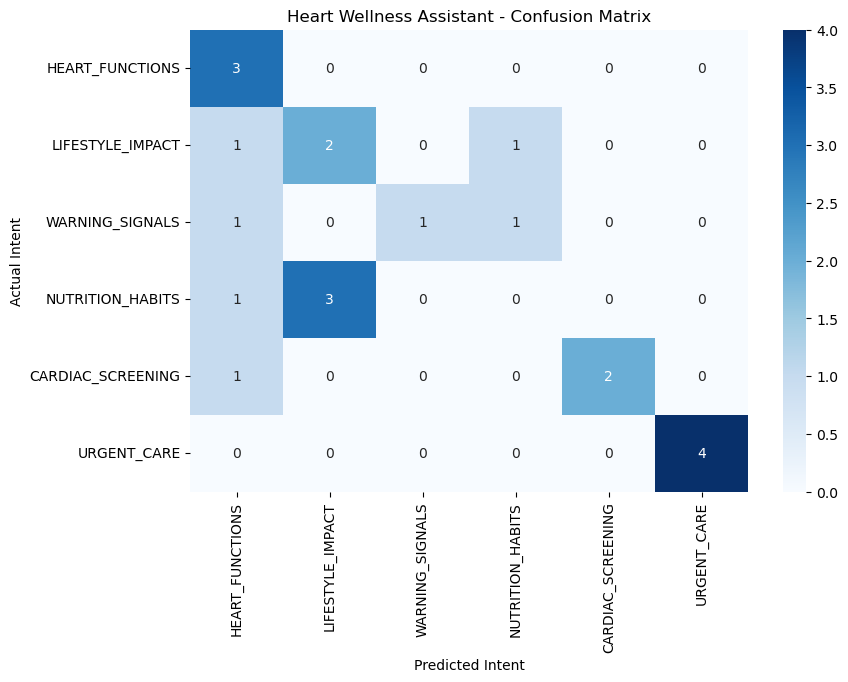

In [25]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(corpus.keys())
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=corpus.keys(),
    yticklabels=corpus.keys()
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Heart Wellness Assistant - Confusion Matrix")
plt.show()

In [19]:
additional_queries = {
    "HEART_FUNCTIONS": [
        "How does the heart send blood to the lungs?",
        "What happens during a normal heartbeat?",
        "Why are heart valves important for circulation?",
        "How does the heart respond to physical effort?",
        "What is the role of the left ventricle?",
        "How does the heart receive oxygen?"
    ],

    "LIFESTYLE_IMPACT": [
        "Can irregular sleeping habits affect cardiovascular health?",
        "How does a sedentary routine influence the heart?",
        "Why is stress management important for the heart?",
        "Can cycling improve cardiovascular fitness?",
        "Does smoking narrow blood vessels?",
        "How does weight management support heart wellness?"
    ],

    "WARNING_SIGNALS": [
        "Why does my heart sometimes race unexpectedly?",
        "Can breathlessness be associated with cardiac conditions?",
        "What does persistent ankle swelling suggest?",
        "Can dizziness occur with an abnormal heartbeat?",
        "Why should recurring chest discomfort be checked?",
        "What are unusual changes in pulse rate?"
    ],

    "NUTRITION_HABITS": [
        "Which foods help maintain healthy blood vessels?",
        "Can excess sodium contribute to hypertension?",
        "How do whole grains support heart health?",
        "Why are unsaturated fats preferred in a heart healthy diet?",
        "Can excessive sugar intake affect cardiovascular wellness?",
        "What are some examples of fibre rich foods?"
    ],

    "CARDIAC_SCREENING": [
        "How is an irregular heartbeat detected?",
        "What does a lipid test measure?",
        "Can an ECG identify electrical changes in the heart?",
        "Why might a doctor suggest continuous heart monitoring?",
        "How does an ultrasound examine the heart?",
        "What is the purpose of ambulatory blood pressure monitoring?"
    ],

    "URGENT_CARE": [
        "What should I do if someone suddenly develops chest pressure?",
        "How quickly should a suspected heart attack be treated?",
        "What should I do if a person is unconscious?",
        "Should I seek emergency help for sudden severe breathlessness?",
        "What action is needed when chest pain spreads to the arm?",
        "Why is immediate treatment important during cardiac emergencies?"
    ]
}

for intent, questions in additional_queries.items():
    corpus[intent].extend(questions)

print("Additional questions added successfully!")

Additional questions added successfully!


In [20]:
queries = []
labels = []

for intent, questions in corpus.items():
    for question in questions:
        queries.append(question)
        labels.append(intent)

print("Total Queries:", len(queries))

for intent, questions in corpus.items():
    print(intent, ":", len(questions))

Total Queries: 84
HEART_FUNCTIONS : 14
LIFESTYLE_IMPACT : 14
WARNING_SIGNALS : 14
NUTRITION_HABITS : 14
CARDIAC_SCREENING : 14
URGENT_CARE : 14


In [21]:
clean_queries = []

for query in queries:
    clean_queries.append(preprocess_text(query))

print("Processed Queries:", len(clean_queries))

Processed Queries: 84


In [26]:
def check_emergency(query):

    emergency_phrases = [
        "heart attack",
        "sudden chest pressure",
        "severe chest pain",
        "chest pain spreading",
        "chest pain to the jaw",
        "severe breathing difficulty",
        "difficulty breathing",
        "unconscious",
        "not responding",
        "person collapses",
        "chest pain and sweating"
    ]

    query = query.lower()

    return any(phrase in query for phrase in emergency_phrases)


def is_greeting(query):

    greetings = [
        "hi", "hello", "hey",
        "good morning", "good evening"
    ]

    return query.lower().strip() in greetings


def is_supported_topic(query):

    keywords = [
        "heart", "cardiac", "blood", "circulation",
        "heartbeat", "rhythm", "chest", "artery",
        "pressure", "cholesterol", "sleep", "stress",
        "exercise", "walking", "activity", "tobacco",
        "diet", "salt", "sugar", "fat", "fibre",
        "oats", "fruits", "nuts", "ecg", "ekg",
        "holter", "echocardiogram", "screening",
        "breathing", "dizzy", "fatigue", "swelling",
        "unconscious", "attack", "valves", "chambers"
    ]

    query = query.lower()

    return any(word in query for word in keywords)


print("Reasoning rules created successfully!")

Reasoning rules created successfully!


In [35]:
def heart_health_assistant(query):

    if not query.strip():
        return "Please enter a question."

    if is_greeting(query):
        return (
            "Hello! Welcome to the Heart Wellness Assistant. "
            "Ask me about heart functions, lifestyle, nutrition "
            "or cardiac screening."
        )

    if check_emergency(query):
        return (
            "EMERGENCY ALERT: Your message describes potentially "
            "serious symptoms. Contact emergency services immediately. "
            "In India, call 112. Do not delay medical attention."
        )

    if not is_supported_topic(query):
        return (
            "Sorry, I can only answer questions about heart functions, "
            "lifestyle influences, warning signals, nutrition habits, "
            "cardiac screening and urgent care."
        )

    text = query.lower()

    # Rule-based intent identification
    if any(word in text for word in [
        "fluttering", "palpitation", "dizziness",
        "lightheaded", "breathless", "swelling",
        "faint", "chest tightness", "unusual tiredness"
    ]):
        predicted_intent = "WARNING_SIGNALS"
        method = "Rule-based reasoning"

    elif any(word in text for word in [
        "oats", "fruits", "nuts", "fibre", "fiber",
        "salt", "sugar", "saturated fat", "diet",
        "whole grains"
    ]):
        predicted_intent = "NUTRITION_HABITS"
        method = "Rule-based reasoning"

    else:
        processed_query = preprocess_text(query)
        probabilities = model.predict_proba([processed_query])[0]
        confidence = max(probabilities)

        if confidence < 0.20:
            return (
                "I could not confidently understand your question. "
                "Please rephrase it using words related to heart wellness."
            )

        predicted_intent = model.predict([processed_query])[0]
        method = "Machine learning"

    response = knowledge_base[predicted_intent]

    return (
        response
        + "\n\nPredicted Intent: " + predicted_intent
        + "\nIdentification Method: " + method
    )


print("Improved Heart Wellness Assistant integrated successfully!")

Improved Heart Wellness Assistant integrated successfully!


In [36]:
test_questions = [
    "How do heart chambers work together?",
    "Can poor sleep affect cardiovascular health?",
    "What could frequent heart fluttering indicate?",
    "Are oats beneficial for heart health?",
    "What can a Holter monitor detect?",
    "I have sudden severe chest pain.",
    "Explain quantum physics."
]

for question in test_questions:

    print("User:", question)
    print("Assistant:", heart_health_assistant(question))
    print("-" * 70)

User: How do heart chambers work together?
Assistant: The heart works as a muscular pump. Its four chambers coordinate to move blood through the lungs and the rest of the body. Heart valves help maintain the direction of blood flow.

Predicted Intent: HEART_FUNCTIONS
Identification Method: Machine learning
----------------------------------------------------------------------
User: Can poor sleep affect cardiovascular health?
Assistant: Daily habits influence cardiovascular wellness. Regular movement, adequate sleep, stress management and avoiding tobacco can support a healthier heart.

Predicted Intent: LIFESTYLE_IMPACT
Identification Method: Machine learning
----------------------------------------------------------------------
User: What could frequent heart fluttering indicate?
Assistant: Possible warning signals include unusual breathlessness, chest discomfort, dizziness, unexplained fatigue, ankle swelling and changes in heartbeat. These symptoms need appropriate medical assessme

In [38]:
rule_tests = [
    "",
    "Hello",
    "What is quantum physics?",
    "I feel dizzy sometimes.",
    "A person is unconscious and not responding."
]

for question in rule_tests:

    print("User:", question if question else "(Empty input)")
    print("Assistant:", heart_health_assistant(question))
    print("-" * 70)

User: (Empty input)
Assistant: Please enter a question.
----------------------------------------------------------------------
User: Hello
Assistant: Hello! Welcome to the Heart Wellness Assistant. Ask me about heart functions, lifestyle, nutrition or cardiac screening.
----------------------------------------------------------------------
User: What is quantum physics?
Assistant: Sorry, I can only answer questions about heart functions, lifestyle influences, warning signals, nutrition habits, cardiac screening and urgent care.
----------------------------------------------------------------------
User: I feel dizzy sometimes.
Assistant: Possible warning signals include unusual breathlessness, chest discomfort, dizziness, unexplained fatigue, ankle swelling and changes in heartbeat. These symptoms need appropriate medical assessment.

Predicted Intent: WARNING_SIGNALS
Identification Method: Machine learning
----------------------------------------------------------------------
User: A 

In [39]:
import gradio as gr

demo = gr.Interface(
    fn=heart_health_assistant,

    inputs=gr.Textbox(
        lines=2,
        placeholder="Ask a question about heart health...",
        label="Enter Your Question"
    ),

    outputs=gr.Textbox(
        lines=6,
        label="Assistant Response"
    ),

    title="Heart Wellness Information Assistant",

    description=(
        "An educational assistant that uses NLP, "
        "machine learning and rule-based reasoning "
        "to answer heart wellness questions. "
        "It is not a substitute for professional medical advice."
    )
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
